# Figure: the time horizon of individuality

How far back in training a mouse's proficient behaviour can be seen. All behaviour here is the **left paw + wheel** dataset (one camera, so every timepoint is comparable): syllables `left_paw_wheel_k8_stages`, states `left_paw_wheel_states_uniform_raw_sessionz_fit-stages` (one state space fitted on a stage-balanced pool), with that state set's own palette.

| panel | what | source |
|---|---|---|
| a | where the datasets sit in training: every task session of six example mice spanning the range of training length (grey ticks), the sessions analysed coloured by timepoint | `learning_individuality/dataset_timepoints_overview.ipynb` panel A |
| b | the left paw + wheel states: vigor, and left-paw minus wheel power (which source leads the state) | `state_palette.csv` of the state set |
| c | a shrinkage LDA trained on Proficient sessions identifies the mouse from an earlier session; bars = accuracy (95 % CI over mice), dashed = shuffled-label null, diamond = held-out Proficient sessions | `learning_individuality/lda_sweep_timepoints.ipynb` (PASS 2) |
| d | syllable × trial-bin correlation across mice with Proficient, per timepoint, and the split-half Proficient ceiling | `learning_individuality/syllable_correlations.ipynb` |
| e | session-wide measures (fraction of time whisking / licking from the HMMs, left-paw vigor from the states): each timepoint against Proficient across mice, and Proficient against itself (odd vs even sessions) | as `cosyne_figure.ipynb` |

Writes `figure_generation/figures/fig_time_horizon.pdf` and a dated SVG.

In [1]:
import sys, pathlib, re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
import matplotlib as mpl

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(PI / 'neural'), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
# the LDA file was pickled under numpy 2; under numpy 1 its module paths need aliasing to unpickle
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import fig_layout as fl
ps.use('paper')
FIG = 'fig_time_horizon'
CACHE = FIGDIR / 'cache'

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Running the source notebooks

`load_panels` executes a notebook's code cells in order into a fresh namespace, stopping at its assembly cell or after the cell containing `stop_after`; `plt.show` is replaced by a close meanwhile.

In [2]:
import json

def load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    """The notebook's namespace, or None if its inputs are not on this machine (the panels it feeds are then
    drawn as labelled placeholders, so the layout can still be checked)."""
    try:
        return _load_panels(name, subs, stop_after, path, cwd)
    except (FileNotFoundError, OSError) as e:
        plt.show = _SHOW; plt.close('all'); ps.use('paper')
        print(f'{name}: NOT loaded -- missing input: {e}')
        return None

_SHOW = plt.show

def _load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    import os
    nb = json.load(open(path or FIGDIR / f'{name}.ipynb'))
    here = os.getcwd()
    if cwd:
        os.chdir(cwd)
    ns = {'__name__': f'fig_time_horizon_{name}'}
    show = _SHOW
    plt.show = lambda *a, **k: plt.close('all')
    try:
        for c in nb['cells']:
            if c['cell_type'] != 'code':
                continue
            src = ''.join(c['source'])
            if 'place_letters' in src or 'fig.savefig(path)' in src:
                break
            for a, b in (subs or {}).items():
                src = src.replace(a, b)
            exec(compile(src, f'{name}.ipynb', 'exec'), ns)
            if stop_after and stop_after in src:
                break
    finally:
        os.chdir(here)
        plt.show = show
        plt.close('all')
    ps.use('paper')
    print(f'{name}: loaded')
    return ns



## a — timepoints in training (six example mice)

In [3]:
TL = load_panels('dataset_timepoints_overview', path=PI / 'learning_individuality' / 'dataset_timepoints_overview.ipynb',
                 cwd=PI / 'learning_individuality', stop_after='def trajectory_panel',
                 subs={'SHOW_LEARNING_CURVE = True': 'SHOW_LEARNING_CURVE = False', 'N_MICE = 12': 'N_MICE = 6'})

def draw_a(fig, spec):
    ax = fig.add_subplot(spec)
    mice = list(TL['EXAMPLES'])
    np.random.default_rng(3).shuffle(mice)      # spanning training length, but not shown in that order
    TL['trajectory_panel'](ax, mice)
    ax.set_yticklabels([f'Mouse {k + 1}' for k in range(len(mice))])
    ax.tick_params(axis='y', length=0)
    h, l = ax.get_legend_handles_labels()       # the timepoints' full names (dataset_timepoints_overview's labels)
    ax.legend(h, l, frameon=False, ncol=2, loc='lower left', bbox_to_anchor=(0, 1.0),   # 2 x 2: one row ran into b
              fontsize=plt.rcParams['legend.fontsize'] * 0.9, handlelength=0.6, handletextpad=0.1,
              columnspacing=0.6, labelspacing=0.1, borderaxespad=0.05, borderpad=0)
    return [ax]

paper_style: poster mode, spines=lb, font 16 pt, panels 7.0x5.0 in, save 300 dpi
57 mice with all four timepoints placed on a session axis
total task sessions per mouse: median 56, range 26-152

session number of each dataset:
            count   min   25%   50%   75%    max
timepoint                                       
Early        57.0   1.0   1.0   1.0   1.0    1.0
Late         57.0   5.0  14.0  22.0  37.0   60.0
Pre-rec     171.0  17.0  36.0  45.0  64.0  130.0
Proficient  270.0  23.0  42.0  54.0  76.0  147.0

example mice (6), fastest -> slowest:
  ZFM-01592       26 sessions
  CSH_ZAD_026     42 sessions
  NYU-47          48 sessions
  PL017           61 sessions
  CSHL045         77 sessions
  PL015          152 sessions
not saved (ps.SAVE_FIGURES is False): figures/timepoints_example_trajectories_poster_19-10-2026.png, figures/timepoints_example_trajectories_poster_19-10-2026.svg   -- ps.saving(True) to write, or pass save=True
paper_style: paper mode, spines=lb, font 8 pt, p

## b — the left paw + wheel states

Per state (numbered by vigor, 0 stillest), from the state set's `state_palette.csv`: its vigor (mean z power) and left-paw power minus wheel power — positive = the paw leads, negative = the wheel leads. Colours are that palette's.

In [4]:
PAW_STATES_DIR = PI / 'data' / 'left_paw_wheel_states_uniform_raw_sessionz_fit-stages'
PAL = pd.read_csv(PAW_STATES_DIR / 'state_palette.csv').set_index('state').sort_index()
print(PAL.round(3).to_string())

def draw_b(fig, spec):
    g = spec.subgridspec(1, 2, wspace=0.35)
    ypos = -np.arange(len(PAL))
    axes = []
    for j, (col, title, xlab) in enumerate([('vigor', 'Vigor', 'z power'), ('gap', 'Paw − wheel', '← wheel    paw →')]):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        vals = PAL[col].to_numpy()
        ax.barh(ypos, vals, height=0.74, color=PAL['colour'], edgecolor='#333333', lw=0.4)
        ax.axvline(0, color='#333333', lw=0.6)
        m = np.abs(vals).max() * 1.15
        ax.set_xlim(min(vals.min() * 1.3, -0.1 * m) if col == 'vigor' else -m, m)
        ax.set_title(title, fontsize=plt.rcParams['font.size'])
        ax.set_xlabel(xlab, fontsize=plt.rcParams['font.size'] * 0.9)
    axes[0].set_yticks(ypos); axes[0].set_yticklabels([str(s) for s in PAL.index])
    axes[0].set_ylabel('Paw + wheel state')
    axes[1].tick_params(labelleft=False)
    return axes

       vigor  left_paw power  wheel power  share    gap   colour
state                                                           
0     -0.540          -0.534       -0.554  0.424  0.021  #EDE4F5
1     -0.130          -0.124       -0.142  0.240  0.018  #BEB6C5
2      0.256           0.043        0.683  0.117 -0.640  #09B8A2
3      0.663           0.749        0.490  0.077  0.259  #997EAE
4      0.785           1.005        0.345  0.068  0.661  #9B5BC5
5      1.307           1.004        1.914  0.043 -0.910  #037B6C
6      2.052           2.284        1.588  0.022  0.696  #732E9B
7      2.607           3.406        1.009  0.009  2.397  #460066


## c — identifying the mouse from an earlier session (Proficient-trained LDA)

Transcribed from the stored output of `lda_sweep_timepoints.ipynb` PASS 2 (left paw + wheel syllables, per-timepoint mice). Its PASS 3 (leave-one-session-out Proficient ceiling) has no stored result, so the ceiling shown is PASS 2's held-out Proficient sessions of the same mice.

In [5]:
TIMEPOINTS_RESULT = pd.DataFrame([
    dict(tp='Early', acc=0.0289, lo=0.0008, hi=0.0749, null=0.0270, p=0.2438, prof=0.9228, n_mice=37),
    dict(tp='Late', acc=0.0924, lo=0.0353, hi=0.1676, null=0.0205, p=0.004975, prof=0.8912, n_mice=49),
    dict(tp='Pre-rec', acc=0.5333, lo=0.4203, hi=0.6502, null=0.0286, p=0.004975, prof=0.8654, n_mice=37),
]).set_index('tp')

def draw_c(fig, spec):
    from matplotlib.lines import Line2D
    ax = fig.add_subplot(spec)
    for k, (tp, r) in enumerate(TIMEPOINTS_RESULT.iterrows()):
        ax.bar(k, r['acc'], width=0.68, color=ps.TIMEPOINT[tp])
        ax.errorbar(k, r['acc'], yerr=[[r['acc'] - r['lo']], [r['hi'] - r['acc']]], fmt='none', ecolor='0.15', lw=0.7)
        ax.plot([k - 0.34, k + 0.34], [r['null']] * 2, color='0.2', ls='--', lw=0.7)
        ax.plot(k, r['prof'], 'D', ms=3.5, color=ps.TIMEPOINT['Proficient'], mec='white', mew=0.4)
        ax.text(k, r['hi'] + 0.03, ps.stars(r['p']), ha='center', va='bottom')
    ax.set_xticks(range(len(TIMEPOINTS_RESULT))); ax.set_xticklabels(TIMEPOINTS_RESULT.index)
    for t, tp in zip(ax.get_xticklabels(), TIMEPOINTS_RESULT.index):
        t.set_color(ps.TIMEPOINT[tp])
    ax.set_ylim(0, 1.3); ax.set_yticks([0, 0.5, 1]); ax.set_ylabel('Mouse ID accuracy\n(Proficient-trained LDA)')
    ax.legend(handles=[Line2D([], [], marker='D', ls='none', ms=3.5, color=ps.TIMEPOINT['Proficient'], label='held-out Proficient'),
                       Line2D([], [], ls='--', color='0.2', lw=0.7, label='shuffled labels')],
              frameon=False, loc='upper left', handlelength=1.2, borderaxespad=0)
    return [ax]

## d — where in the trial individuality persists

`syllable_correlations.ipynb` run up to its correlation cell: per syllable and trial bin, Spearman across mice between each timepoint and Proficient (sessions averaged within mouse; mice present at both), and the split-half ceiling within Proficient. Colours = `ps.CORR_CMAP`, the paper's correlation map, one colour scale for the four maps.

In [6]:
SC = load_panels('syllable_correlations', path=PI / 'learning_individuality' / 'syllable_correlations.ipynb',
                 cwd=PI / 'learning_individuality', stop_after='def split_half_reliability')
print({tp: SC['CORR'][tp]['n'] for tp in SC['TPS']}, 'ceiling n =', SC['CEIL']['n'])

def draw_d(fig, spec):
    maps = [(tp, SC['CORR'][tp]['r'], f"{tp} ({SC['CORR'][tp]['n']})") for tp in SC['TPS']]
    maps.append(('ceiling', SC['CEIL']['r'], f"Prof. halves ({SC['CEIL']['n']})"))
    vmax = float(np.nanmax([np.nanmax(np.abs(R)) for _, R, _ in maps]))
    g = spec.subgridspec(1, len(maps) + 1, width_ratios=[1] * len(maps) + [0.05], wspace=0.12)
    axes = []
    n_bins = SC['N_BINS']; per = n_bins // 4
    for j, (tp, R, ttl) in enumerate(maps):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        im = ax.imshow(R.T, aspect='auto', cmap=ps.CORR_CMAP, norm=ps.corr_norm(vmax), interpolation='nearest')
        for e in SC['EPOCH_EDGES']:
            ax.axvline(e - 0.5, color='k', lw=0.5)
        ax.set_xticks([per * (i + 0.5) - 0.5 for i in range(4)]); ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right',
                                                                                  rotation_mode='anchor')
        ax.set_title(ttl, fontsize=plt.rcParams['font.size'],
                     color=ps.TIMEPOINT.get(tp, ps.TIMEPOINT['Proficient']))
        ax.tick_params(length=0)
        if j:
            ax.tick_params(labelleft=False)
    names = list(SC['FEATURE_NAMES'])
    axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels(names)
    for t, c in zip(axes[0].get_yticklabels(), SC['FEATURE_COLORS']):   # a swatch of each syllable's colour
        t.set_bbox(dict(facecolor=c, edgecolor='none', boxstyle='square,pad=0.15', alpha=0.9))
        rgb = mpl.colors.to_rgb(c)
        if 0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2] < 0.5:      # dark swatch: white text
            t.set_color('white')
    cax = fig.add_subplot(g[-1])
    cb = fig.colorbar(im, cax=cax); cb.outline.set_visible(False)
    cb.set_label('r with Proficient (across mice)', labelpad=1)
    return axes + [cax]

paper_style: poster mode, spines=lb, font 16 pt, panels 7.0x5.0 in, save 300 dpi


base_path: /home/ines/repositories/representation_learning_variability/paper-individuality/data/


syllables: left_paw_wheel k=8, state space 'stages', lick HMM 'auto', 10 bins/phase
exclusions from the sheet (filtered_out): Early 15, Late 9, Pre-rec 76, Proficient 12, Habituation 0
  OK   Early left_paw_wheel_k8_stages_lick-100ms_session_1_8_k_10_bin_syllables_06-10-2026
  OK   Late left_paw_wheel_k8_stages_lick-100ms_last_training_8_k_10_bin_syllables_06-10-2026
  OK   Pre-rec left_paw_wheel_k8_stages_lick-100ms_biased_8_k_10_bin_syllables_06-10-2026
  OK   Proficient left_paw_wheel_k8_stages_lick-standard_proficient_8_k_10_bin_syllables_06-10-2026
  Early         47 sessions ->   47 after prob_sessions/min_sessions ->   37 after the Early exclusion list (0 + 10 dropped)


  Late          55 sessions ->   55 after prob_sessions/min_sessions ->   49 after the Late exclusion list (0 + 6 dropped)


  Pre-rec      116 sessions ->  116 after prob_sessions/min_sessions ->   96 after the Pre-rec exclusion list (0 + 20 dropped)


  Proficient   332 sessions ->  330 after prob_sessions/min_sessions ->  330 after the Proficient exclusion list (2 + 0 dropped)


OK 512 sessions, 360 features, 101 mice
            sessions  mice
timepoint                 
Early             37    37
Late              49    49
Pre-rec           96    37
Proficient       330   101
state colours: state_palette.csv of left_paw_wheel / stages
reconstructed: 512 sessions x 40 trial bins x 10 features (reference states restored)
  Early        37 mice
  Late         49 mice
  Pre-rec      37 mice
  Proficient  101 mice


ceiling: 76 mice with >= 2 Proficient sessions, 200 splits

mean r over trial bins (spearman, vs Proficient)
modality        Early       Late    Pre-rec   ceiling
Paw             0.089      0.148      0.515     0.596
Whisk           0.209      0.323      0.663     0.776
Lick            0.240      0.331      0.669     0.787

mice shared with Proficient: Early n=37, Late n=49, Pre-rec n=37
flat cells (no variance across mice -> r = 0, no CI): Early 0/400, Late 2/400, Pre-rec 0/400
   Late: Quiescence / Paw 5
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
syllable_correlations: loaded
{'Early': 37, 'Late': 49, 'Pre-rec': 37} ceiling n = 76


## e — session-wide measures against Proficient

As the last panel of `cosyne_figure.ipynb`: whisking and licking = fraction of time in the active HMM state, paw = left-paw vigor from the left paw + wheel states (session-wide averages, not trial-resolved). Each earlier timepoint's per-mouse mean against the same mouse's Proficient mean (Spearman across mice); Prof. = odd vs even Proficient sessions (the reliability ceiling). Filled = BH FDR q < 0.05; grey band = recorded on the recording rig.

In [7]:
# Proficient as the anchor: per mouse, the mean of each measure at every earlier timepoint, Spearman with the same
# mouse's Proficient mean (every mouse with both timepoints, so n differs per point). BH FDR over the tests drawn.
#   whisking, licking: fraction of time in the active HMM state (occupancy; habituation/3_hmm_state_measures.py's
#     per-session measures, its fit screens). The whisking HMM runs on session-z-scored motion energy, so camera
#     gain / distance drop out; Proficient's fits are the older 60 Hz two-camera ones, comparable by rank only.
#   paw: left-paw vigor from the joint left paw + wheel states (segmentation/3.3_wavelet_clusters_uniform, fitted on
#     a stage-balanced pool, session-z-scored wavelets; one state space for every stage): each frame scored by its
#     state's left-paw wavelet power (state_palette.csv), averaged over the session. Session z-scoring removes the
#     session's level, so this is how much of the session sits in high- vs low-left-paw-power states, not raw speed.
#     No states at habituation.
# Proficient vs itself: each mouse's Proficient sessions split by date into odd and even, the two halves' means
# correlated across mice (mice with >= 2 Proficient sessions) -- the session-to-session reliability, a ceiling;
# half the sessions on each side, so it is not inflated relative to the other points.
# Pre-rec is recorded on the same rig as Proficient (the recording rig); the earlier timepoints on the training rig.
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
HABDIR = PI.parent / 'habituation'
DMDIR = PI / 'data' / 'design_matrices'
SHOW_HAB = False   # habituation point (whisking / licking only): off here
HAB_COLOR = '#7F7F7F'
PC_TPS = (['Habituation'] if SHOW_HAB else []) + ['Early', 'Late', 'Pre-rec', 'Proficient']   # paw: never a habituation point
PC_LABELS = [{'Habituation': 'Hab.', 'Proficient': 'Prof.'}.get(t, t) for t in PC_TPS]
PC_FEATS = [('whisk_frac', 'Whisking', '0.55', 'o'), ('lick_frac', 'Licking', '0.1', 's'),
            ('paw_vigor', 'Left-paw vigor', ps.PAW_STATE_COLORS[7], '^')]
STAGE_DIRS = {'Early': DMDIR / '1_camera_setup' / 'session_1', 'Late': DMDIR / '1_camera_setup' / 'last_training',
              'Pre-rec': DMDIR / '1_camera_setup' / 'biased', 'Proficient': DMDIR}
PAW_CACHE = CACHE / 'cosyne_left_paw_vigor_sessions.csv'   # shared with cosyne_figure
PAW_STATES = 'left_paw_wheel_states_uniform_raw_sessionz_fit-stages'

def paw_sessions():
    if PAW_CACHE.exists():
        return pd.read_csv(PAW_CACHE)
    power = pd.read_csv(PI / 'data' / PAW_STATES / 'state_palette.csv').set_index('state')['left_paw power'].to_numpy()
    stage_of = {f.name[14:50]: tp for tp, d in STAGE_DIRS.items() if tp != 'Proficient' for f in d.glob('design_matrix_*')}
    rows = []
    for root, prof in [(PI / 'data', True), (PI / 'data' / 'training', False)]:
        for f in sorted((root / PAW_STATES).glob('most_likely_states_8_*.npy')):
            name = f.stem[len('most_likely_states_8_'):]
            eid, mouse = name[-36:], name[:-36]
            tp = 'Proficient' if prof else stage_of.get(eid)
            if tp is None:
                continue
            s = np.load(f)[0]                      # row 0: state per frame, row 1: bin times
            s = s[~np.isnan(s)].astype(int)
            rows.append(dict(timepoint=tp, eid=eid, mouse_name=mouse, paw_vigor=power[s].mean()))
    out = pd.DataFrame(rows)
    out.to_csv(PAW_CACHE, index=False)
    return out

def prof_corr_table():
    h = pd.read_csv(HABDIR / 'hmm_state_measures.csv')
    stage_of = {f.name[14:50]: tp for tp, d in STAGE_DIRS.items() if tp != 'Proficient' for f in d.glob('design_matrix_*')}
    h['timepoint'] = np.where(h['source'] == 'Training', h['eid'].map(stage_of), h['source'])
    h = h.dropna(subset=['timepoint'])
    h['feature'] = h['var'] + '_frac'
    long = pd.concat([h[['timepoint', 'mouse_name', 'eid', 'feature', 'frac']].rename(columns={'frac': 'value'}),
                      paw_sessions().assign(feature='paw_vigor').rename(columns={'paw_vigor': 'value'})
                      [['timepoint', 'mouse_name', 'eid', 'feature', 'value']]])
    m = long.groupby(['feature', 'timepoint', 'mouse_name'])['value'].mean()
    # Proficient odd / even sessions by date
    prof = long[long['timepoint'] == 'Proficient'].copy()
    prof['date'] = prof['eid'].map(SESSION_DATE)
    prof = prof.dropna(subset=['date']).sort_values(['feature', 'mouse_name', 'date'])
    prof['half'] = prof.groupby(['feature', 'mouse_name']).cumcount() % 2
    halves = prof.groupby(['feature', 'mouse_name', 'half'])['value'].mean().unstack('half').dropna()
    rows = []
    for f, *_ in PC_FEATS:
        w = m.loc[f].unstack(0)
        for tp in PC_TPS:
            if tp == 'Proficient':
                d = halves.loc[f].set_axis(['odd', 'even'], axis=1)
                r = spearmanr(d['odd'], d['even'])
                rows.append(dict(feature=f, tp=tp, rho=r.statistic, p=r.pvalue, n=len(d)))
                continue
            elif tp not in w:
                continue
            else:
                d = w[[tp, 'Proficient']].dropna()
            r = spearmanr(d[tp], d['Proficient'])
            rows.append(dict(feature=f, tp=tp, rho=r.statistic, p=r.pvalue, n=len(d)))
    t = pd.DataFrame(rows)
    t['q'] = multipletests(t['p'], method='fdr_bh')[1]
    return t

sys.path.insert(0, str(PI / 'learning_individuality'))
from session_filters import load_session_table
SESSION_DATE = load_session_table().drop_duplicates('eid').set_index('eid')['date']
PROF_CORR = prof_corr_table()
print(PROF_CORR.round(4).to_string(index=False))

def draw_e(fig, spec):
    ax = fig.add_subplot(spec)
    x = np.arange(len(PC_TPS))
    ax.axvspan(x[-2] - 0.45, x[-1] + 0.45, color='0.93', lw=0, zorder=0)   # Pre-rec and Proficient: recording rig
    ax.axvline(x[-1] - 0.5, color='0.75', lw=0.5, ls=':', zorder=1)        # Proficient vs itself: reliability
    ax.text((x[-2] + x[-1]) / 2, -0.2, 'rec. rig', ha='center', va='bottom', color='0.45')
    ax.axhline(0, color='0.75', lw=0.5, zorder=1)
    for k, (f, label, col, mk) in enumerate(PC_FEATS):
        d = PROF_CORR[PROF_CORR['feature'] == f].set_index('tp').reindex(PC_TPS)
        xs = x + (k - 1) * 0.12
        ax.plot(xs[:-1], d['rho'].to_numpy()[:-1], '-', color=col, lw=0.8, zorder=2)   # Proficient (reliability) unconnected
        for xi, (r_, q_) in zip(xs, d[['rho', 'q']].to_numpy()):
            sig = q_ < 0.05
            ax.plot(xi, r_, mk, ms=3.2, color=col, mfc=col if sig else 'white', mew=0.7, zorder=3)
        ax.plot([], [], mk + '-', color=col, ms=3.2, lw=0.8, label=label)
    ax.set_xticks(x); ax.set_xticklabels(PC_LABELS)
    for t, tp in zip(ax.get_xticklabels(), PC_TPS):   # same colours as the timeline above
        t.set_color(HAB_COLOR if tp == 'Habituation' else ps.TIMEPOINT[tp])
    ax.set_xlim(-0.5, x[-1] + 0.5); ax.set_ylim(-0.22, 1.05); ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel('ρ with Proficient\n(across mice)')
    ax.set_title('Session-wide measures', fontsize=plt.rcParams['font.size'])
    ax.legend(frameon=False, loc='upper left', handlelength=1.0, borderaxespad=0.1, handletextpad=0.3,
              labelspacing=0.15, fontsize=plt.rcParams['legend.fontsize'] * 0.9)   # inside: the empty top left
    return [ax]



   feature         tp    rho      p  n      q
whisk_frac      Early 0.3869 0.0060 49 0.0120
whisk_frac       Late 0.3170 0.0184 55 0.0276
whisk_frac    Pre-rec 0.3748 0.0133 43 0.0228
whisk_frac Proficient 0.7052 0.0000 80 0.0000
 lick_frac      Early 0.3030 0.0385 47 0.0513
 lick_frac       Late 0.1507 0.2720 55 0.3264
 lick_frac    Pre-rec 0.4376 0.0033 43 0.0080
 lick_frac Proficient 0.6729 0.0000 81 0.0000
 paw_vigor      Early 0.1200 0.4115 49 0.4489
 paw_vigor       Late 0.0628 0.6489 55 0.6489
 paw_vigor    Pre-rec 0.5954 0.0000 43 0.0001
 paw_vigor Proficient 0.6402 0.0000 76 0.0000


## The assembled figure

180 mm wide. Row 1: a | b | c. Row 2: d | e.

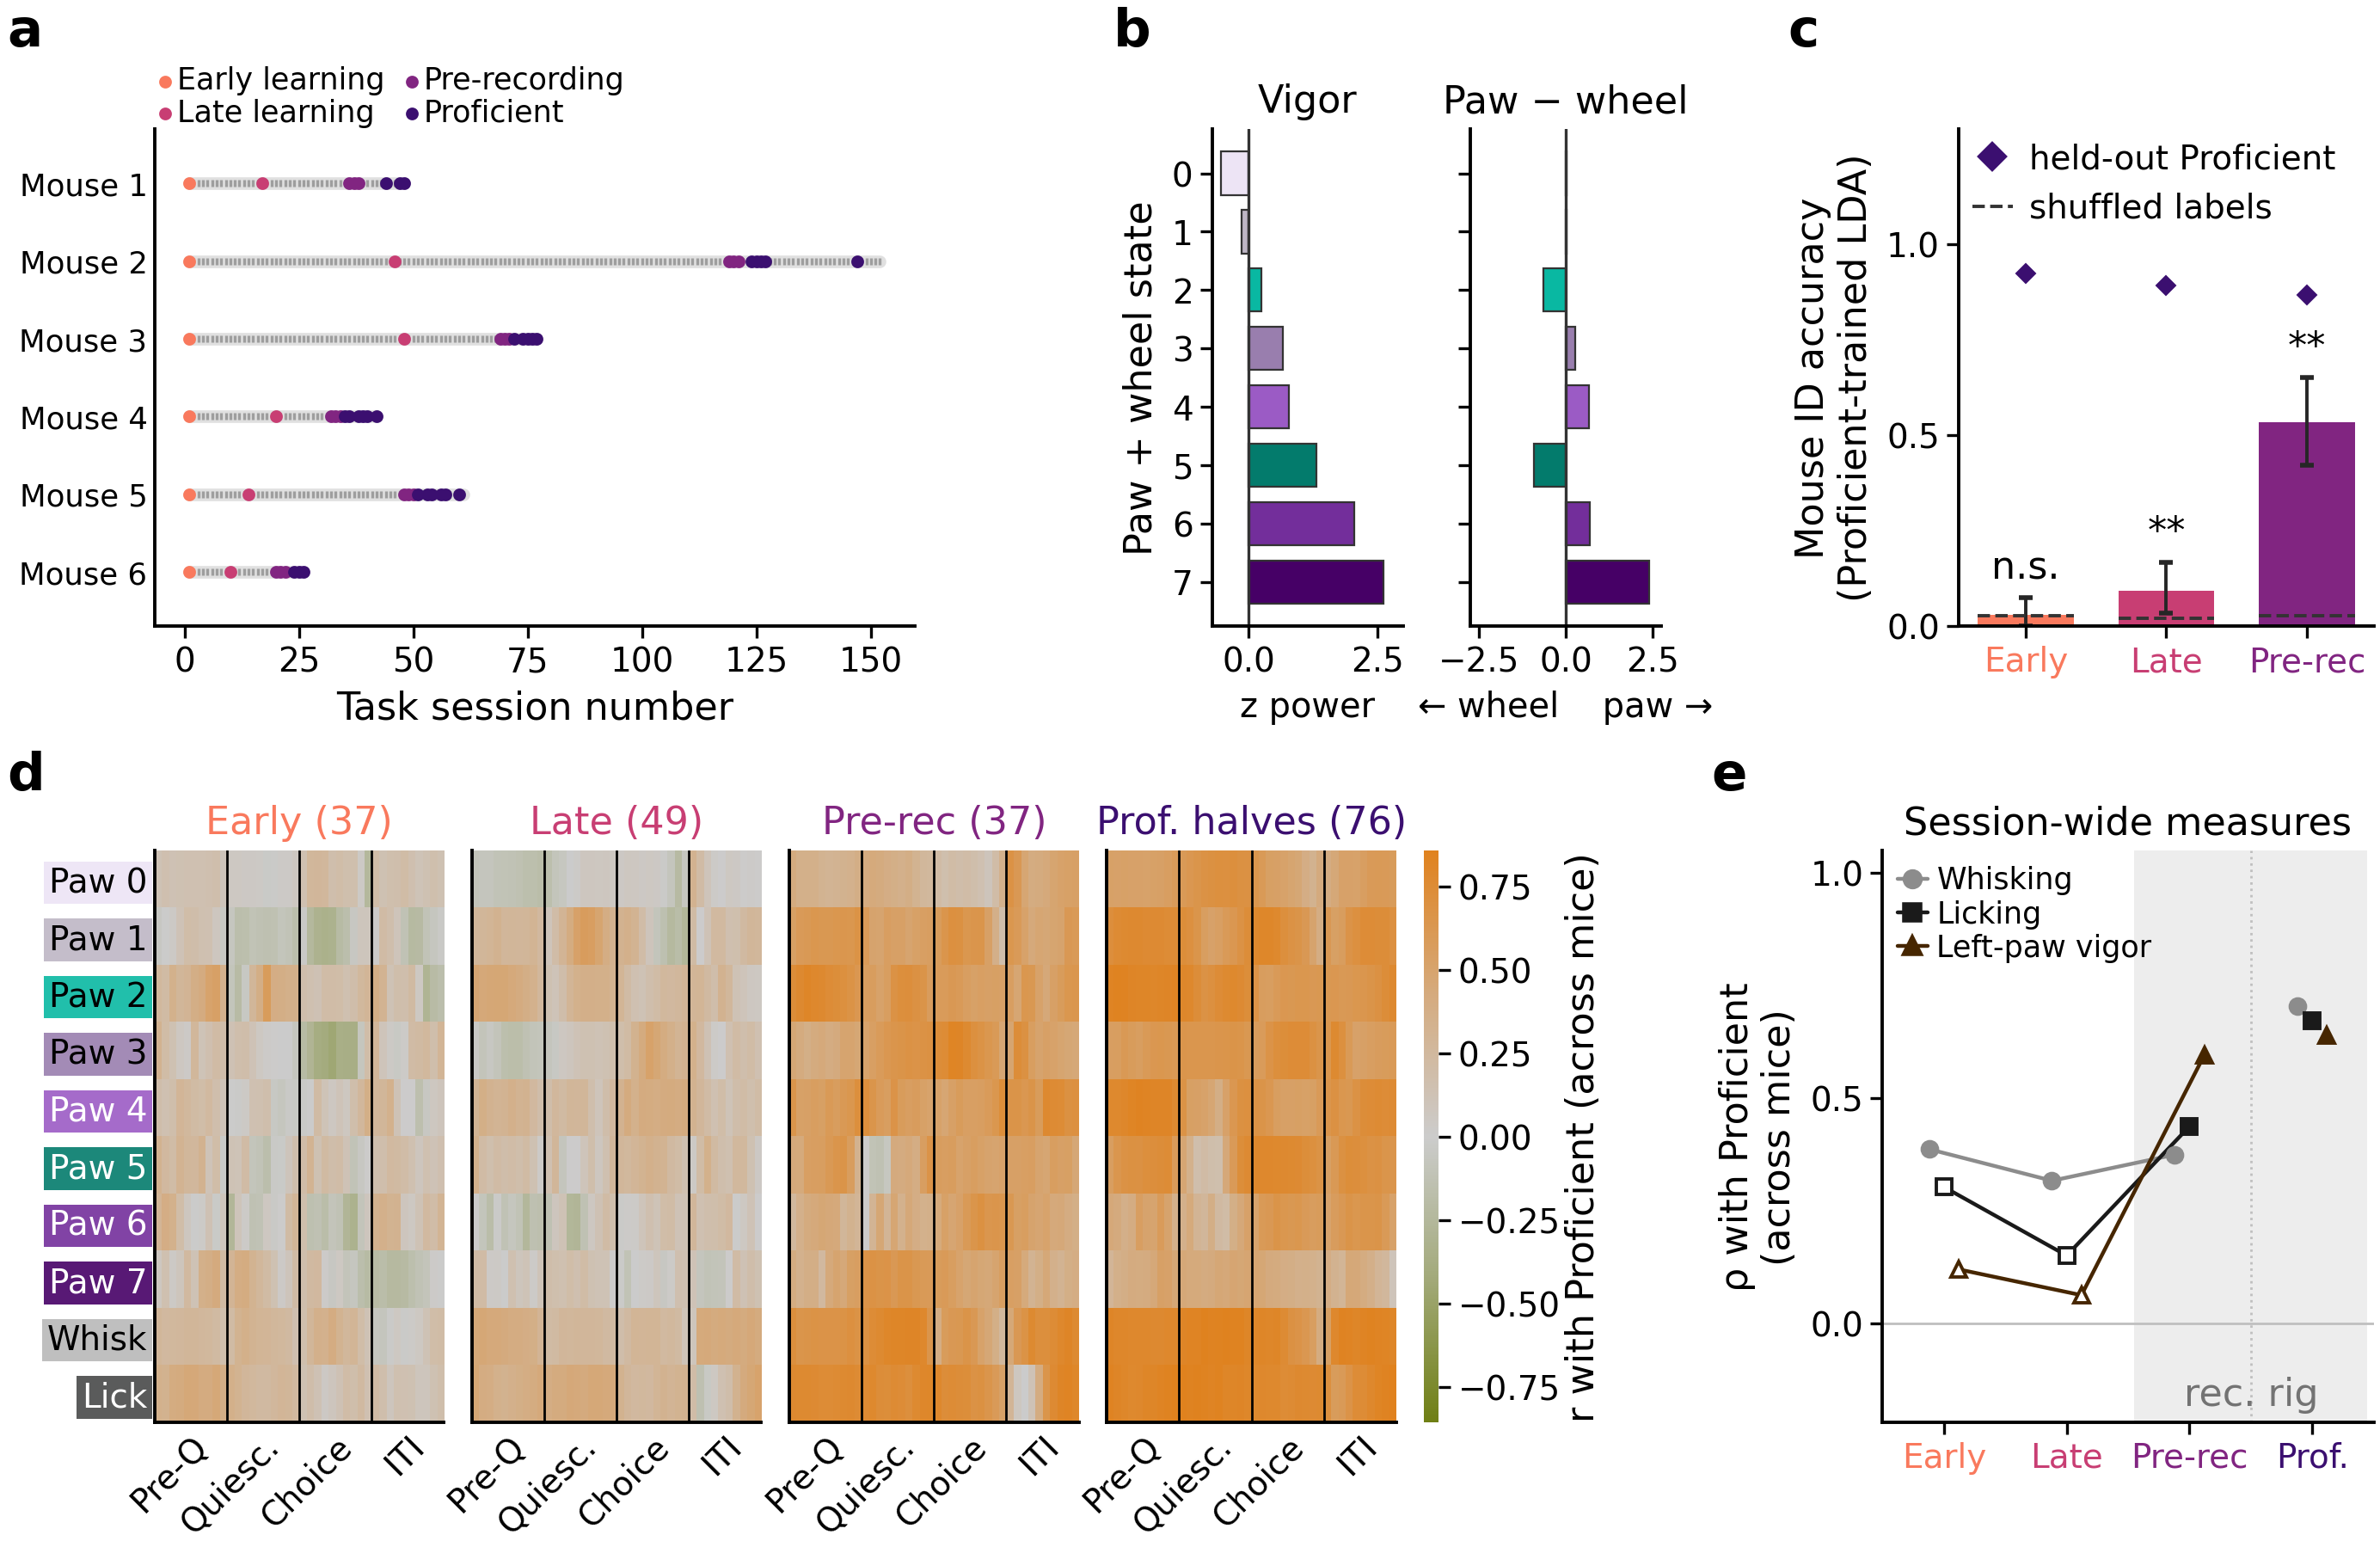

wrote figure_generation/figures/fig_time_horizon_19-10-2026.svg


wrote figure_generation/figures/fig_time_horizon.pdf


In [8]:
from datetime import date
FIG_H = 4.0
fig = plt.figure(figsize=(fl.FIG_WIDTH, FIG_H))
outer = fig.add_gridspec(2, 1, height_ratios=[1, 1.15], hspace=0.42, **fl.MARGINS)
r1 = outer[0].subgridspec(1, 3, width_ratios=[2.2, 1.3, 1.2], wspace=0.55)
r2 = outer[1].subgridspec(1, 2, width_ratios=[3.4, 1.3], wspace=0.5)
panels = {'a': draw_a(fig, r1[0]), 'b': draw_b(fig, r1[1]), 'c': draw_c(fig, r1[2]),
          'd': draw_d(fig, r2[0]), 'e': draw_e(fig, r2[1])}
fl.place_letters(fig, panels, rows=['abc', 'de'], left='ad')
plt.show()

OUT_DIR = FIGDIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
for path in [OUT_DIR / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT_DIR / f'{FIG}.pdf']:
    fig.savefig(path)
    print('wrote', path.relative_to(PI))